Top 10 Longest Tracks:


,track_name,artist,duration_min
710,Lost Boy,Jaden,9.497883
610,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
64,Mirrors,Justin Timberlake,8.069100
63,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
622,Achilles Come Down,Gang of Youths,7.035767
689,Never Let Go (Of Me),Baltra,6.909833
682,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
549,Stan,Eminem,6.735100
671,Galvanize,The Chemical Brothers,6.563550
37,After Hours,The Weeknd,6.017100


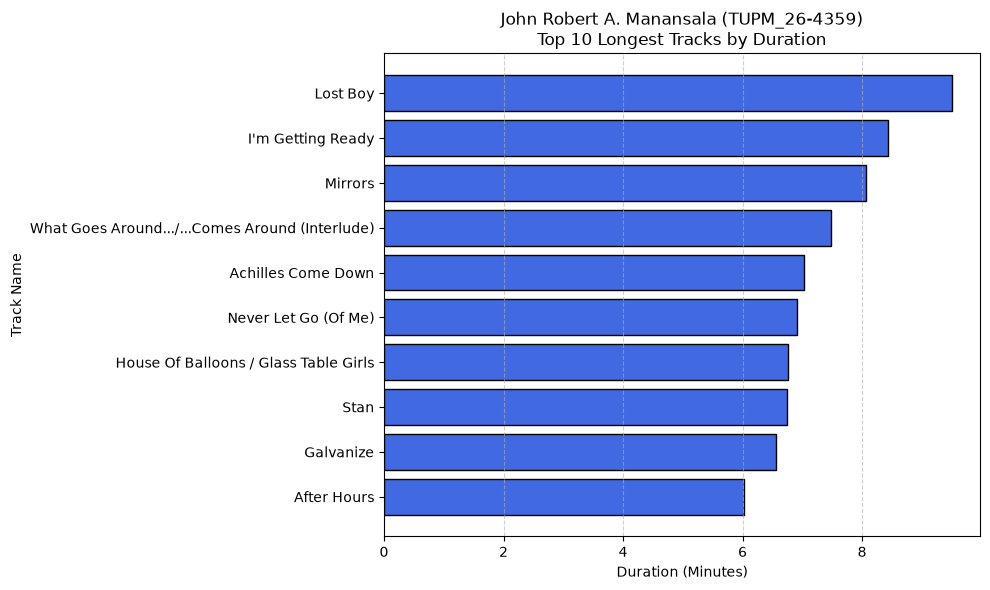

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('spotify_top_1000_tracks.csv')

student_name = "John Robert A. Manansala"
student_id = "TUPM_26-4359"
color_bar = "royalblue" 

top_10_longest = (
    df[['track_name', 'artist', 'duration_min']]
    .sort_values(by='duration_min', ascending=False)
    .head(10)
)

print("Top 10 Longest Tracks:")
display(top_10_longest)  


plt.figure(figsize=(10, 6))
plt.barh(
    top_10_longest['track_name'], 
    top_10_longest['duration_min'], 
    color=color_bar, 
    edgecolor='black'
)


plt.gca().invert_yaxis()


plt.xlabel('Duration (Minutes)')
plt.ylabel('Track Name')
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks by Duration")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


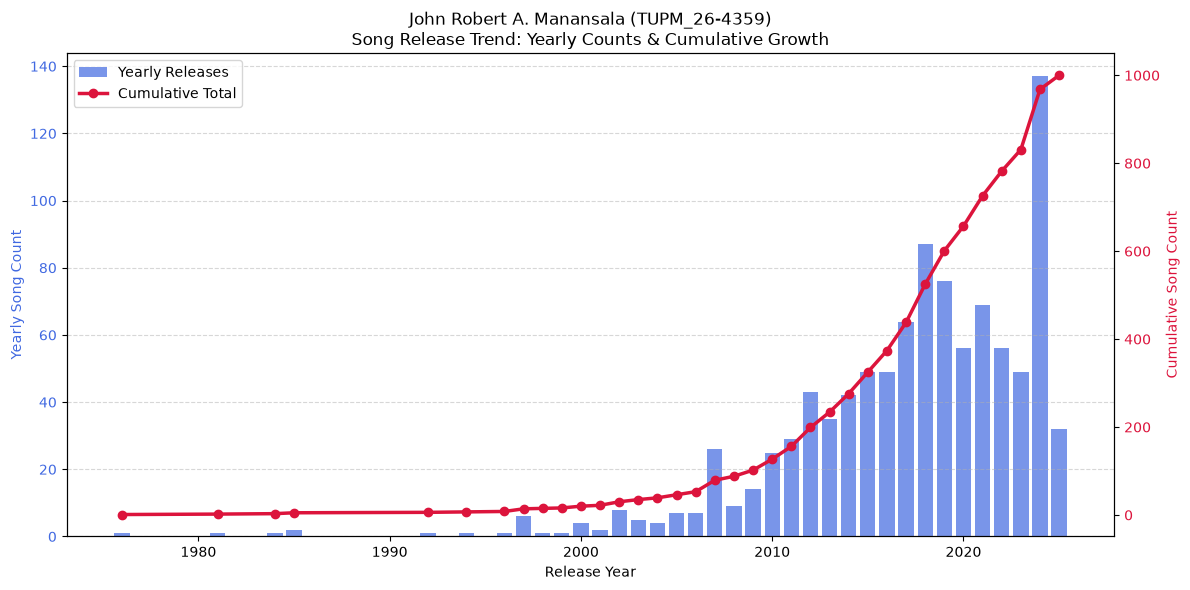

In [17]:
import pandas as pd
import matplotlib.pyplot as plt


student_name = "John Robert A. Manansala"
student_id = "TUPM_26-4359"
color_bar = "royalblue"
color_line = "crimson"


df['year'] = pd.to_datetime(df['release_date'], format='mixed', errors='coerce').dt.year


yearly_trends = (
    df.groupby('year')
    .size()
    .reset_index(name='yearly_count')
    .sort_values('year')
)
yearly_trends['cumulative_count'] = yearly_trends['yearly_count'].cumsum()


fig, ax1 = plt.subplots(figsize=(12, 6))


bars = ax1.bar(
    yearly_trends['year'], 
    yearly_trends['yearly_count'], 
    color=color_bar, 
    alpha=0.7, 
    label='Yearly Releases'
)
ax1.set_xlabel('Release Year')
ax1.set_ylabel('Yearly Song Count', color=color_bar)
ax1.tick_params(axis='y', labelcolor=color_bar)


ax2 = ax1.twinx()
line = ax2.plot(
    yearly_trends['year'], 
    yearly_trends['cumulative_count'], 
    color=color_line, 
    marker='o', 
    linewidth=2.5, 
    label='Cumulative Total'
)
ax2.set_ylabel('Cumulative Song Count', color=color_line)
ax2.tick_params(axis='y', labelcolor=color_line)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')


plt.title(f"{student_name} ({student_id})\nSong Release Trend: Yearly Counts & Cumulative Growth")
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Student-specific parameters
student_name = "John Robert A. Manansala"
student_id = "TUPM_26-4359"
cmap_color = "viridis"  # Other great options: "plasma", "inferno", "magma", "Blues"

# 2. Extract integer 'year' cleanly from 'release_date' and drop missing values
df['year'] = pd.to_datetime(df['release_date'], format='mixed', errors='coerce').dt.year
df_clean = df.dropna(subset=['year', 'duration_min', 'popularity']).copy()
df_clean['year'] = df_clean['year'].astype(int)

# Get sorted list of unique years for animation frames
years = sorted(df_clean['year'].unique())

# Lock axis bounds across all frames so the grid stays steady
x_min, x_max = df_clean['duration_min'].min() - 0.5, df_clean['duration_min'].max() + 0.5
y_min, y_max = max(0, df_clean['popularity'].min() - 5), min(100, df_clean['popularity'].max() + 5)

# 3. Set up the figure and initial hexbin plot (needed to attach the colorbar once)
fig, ax = plt.subplots(figsize=(10, 6))
initial_data = df_clean[df_clean['year'] <= years[0]]

hb = ax.hexbin(
    initial_data['duration_min'],
    initial_data['popularity'],
    gridsize=20,
    cmap=cmap_color,
    extent=[x_min, x_max, y_min, y_max],
    mincnt=1
)
cb = fig.colorbar(hb, ax=ax, label='Song Count (Density)')

# 4. Update function called for each frame (cumulative progression by year)
def update(frame_year):
    ax.clear()
    
    # Subset data up to the current frame_year to show cumulative evolution over time
    subset = df_clean[df_clean['year'] <= frame_year]
    
    hb_frame = ax.hexbin(
        subset['duration_min'],
        subset['popularity'],
        gridsize=20,
        cmap=cmap_color,
        extent=[x_min, x_max, y_min, y_max],
        mincnt=1
    )
    
    # Update colorbar scaling to match the current frame's density
    cb.update_normal(hb_frame)
    
    # Re-apply axis limits, labels, grid, and personalized title on every frame
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Duration (Minutes)')
    ax.set_ylabel('Popularity')
    ax.set_title(
        f"{student_name} ({student_id})\n"
        f"Duration vs Popularity Density Map (Up to Year: {frame_year})"
    )
    ax.grid(True, linestyle='--', alpha=0.4)

# 5. Create and display the interactive HTML5 animation in Jupyter
anim = FuncAnimation(fig, update, frames=years, interval=200, repeat=True)
plt.close(fig)  # Prevents a duplicate static image from printing below the animation
HTML(anim.to_jshtml())
